# Mean squared error as a goodness-of-fit measure
`author` Julien Morin <julien.morin@umontpellier.fr>

`date` 20 Oct 2021

In [1]:
# import and settings
import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as opt

In [2]:
# Generate synthetic measurements
a = 2.
b = 5.
sig0 = 4.
#
x = np.linspace(-10,10,200)
noise = np.random.normal(0., sig0, x.shape)
ymod = a * x + b
ymeas = ymod + noise
# check noise properties
print("mean(noise) = %.4f ; std(noise) = %.4f" % (np.mean(noise), np.std(noise)))

mean(noise) = 0.1092 ; std(noise) = 3.9370


In [3]:
# Define "off" models
a1 = 1.5*a
b1 = b
ymod1 = a1 * x + b1
#
a2 = a
b2 = b + 4.
ymod2 = a2 * x + b2

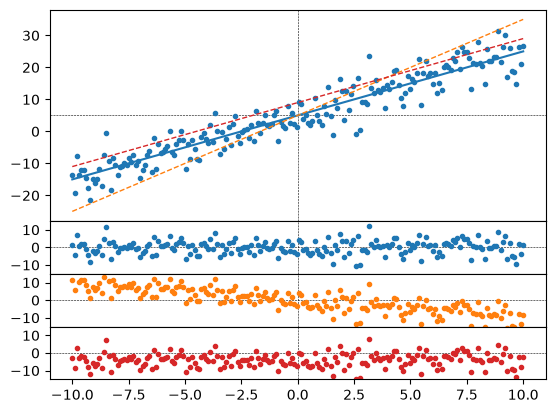

In [4]:
# plot data and model
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, sharex=True, gridspec_kw={'height_ratios': [4, 1, 1, 1]})
fig.subplots_adjust(hspace=0)
# main plot
ax1.axvline(0., ls='--', c='k', lw=0.4)
ax1.axhline(b, ls='--', c='k', lw=0.4)
ax1.plot(x, ymeas, marker='o', ms=3., color='tab:blue', ls='')
ax1.plot(x,ymod, c='tab:blue')
ax1.plot(x,ymod1, c='tab:orange', ls='--', lw=1.)
ax1.plot(x,ymod2, c='tab:red', ls='--', lw=1.)
# residual 'O-C'
ax2.axhline(0., ls='--', c='k', lw=0.4)
ax2.axvline(0., ls='--', c='k', lw=0.4)
ax2.plot(x, ymeas-ymod, 'o', c='tab:blue', ms=3.)
ax2.set_ylim(-15,15)
ax3.axhline(0., ls='--', c='k', lw=0.4)
ax3.axvline(0., ls='--', c='k', lw=0.4)
ax3.plot(x, ymeas-ymod1, 'o', c='tab:orange', ms=3.)
ax3.set_ylim(-15,15)
ax4.axhline(0., ls='--', c='k', lw=0.4)
ax4.axvline(0., ls='--', c='k', lw=0.4)
ax4.plot(x, ymeas-ymod2, 'o', c='tab:red', ms=3.)
ax4.set_ylim(-15,15)
plt.setp(ax1.get_xticklabels(), visible=False)

In [5]:
# Compute and print RMS
rms = np.sqrt(np.mean((ymeas-ymod)**2))
print("RMS = %.4f" % rms)
rms1 = np.sqrt(np.mean((ymeas-ymod1)**2))
print("RMS1 = %.4f" % rms1)
rms2 = np.sqrt(np.mean((ymeas-ymod2)**2))
print("RMS2 = %.4f" % rms2)

RMS = 3.9385
RMS1 = 6.9054
RMS2 = 5.5352
